# 10 — LDA extension: supervised dimensionality reduction on Iris

The workbook includes Linear Discriminant Analysis (LDA) as an extension/flip task. Unlike PCA, LDA uses known species labels and searches for directions that separate classes. This is a separate Iris lab; it does not replace PCA or use the passenger target.


Input: (150, 4) | LDA projection: (150, 2) | class names: ['setosa', 'versicolor', 'virginica']


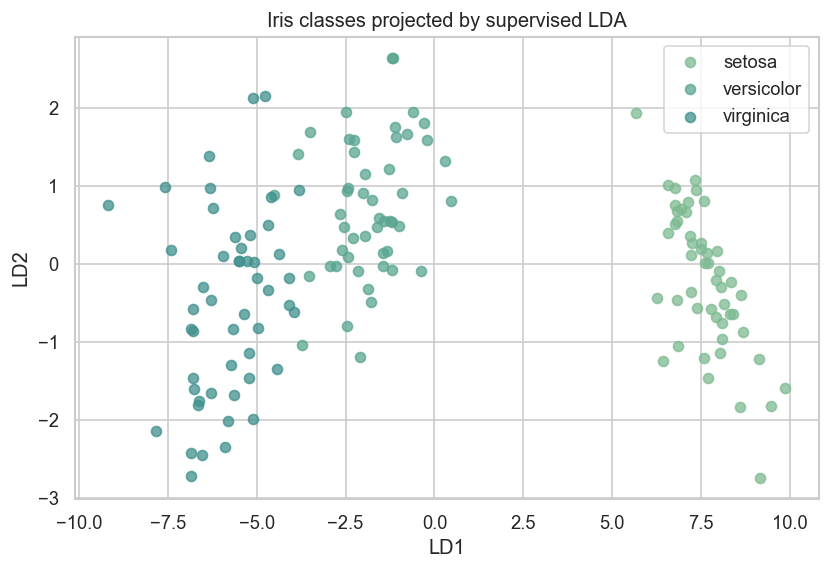

In [1]:
import pandas as pd, matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.linear_model import LogisticRegression

iris=load_iris(); X=pd.DataFrame(iris.data,columns=iris.feature_names); y=iris.target
lda=make_pipeline(StandardScaler(),LinearDiscriminantAnalysis(n_components=2))
Z=lda.fit_transform(X,y)
print('Input:',X.shape,'| LDA projection:',Z.shape,'| class names:',iris.target_names.tolist())
plt.figure(figsize=(8,5))
for i,name in enumerate(iris.target_names): plt.scatter(Z[y==i,0],Z[y==i,1],label=name,alpha=.75)
plt.xlabel('LD1'); plt.ylabel('LD2'); plt.title('Iris classes projected by supervised LDA'); plt.legend(); plt.show()


## Resampling check
The plot is explanatory, but separation on the same rows used to fit a transform can look optimistic. We therefore report a stratified 5-fold classification score for a pipeline that learns scaling and LDA inside each fold. This demonstrates cross-validation without allowing the transform to see validation-fold data.


In [2]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.pipeline import Pipeline
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=42)
pipe=Pipeline([('scale',StandardScaler()),('lda',LinearDiscriminantAnalysis()),('classifier',LogisticRegression(max_iter=1000))])
scores=cross_val_score(pipe,X,y,cv=cv,scoring='accuracy')
print('5-fold accuracy:',scores.round(3),'| mean:',round(scores.mean(),3),'| std:',round(scores.std(),3))


5-fold accuracy: [1.  1.  0.9 1.  1. ] | mean: 0.98 | std: 0.04


## Compare the two methods
PCA ignores species labels and preserves directions with high overall variance. LDA uses labels and tries to separate known species. LDA is appropriate when labels exist and the goal is class separation; it cannot be used in the same way for unlabeled data. Iris has three classes, so at most two discriminant axes are available.
